# Lab 05 - Super-resolution autoencoder on EO image

Use a Sentinel-2 patch, degrade it (low-res), train a small **autoencoder** to recover high-res, compare.


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.04729813..1.0541015].


MSE vs HR — bicubic: 0.01231 | AE SR: 0.01038


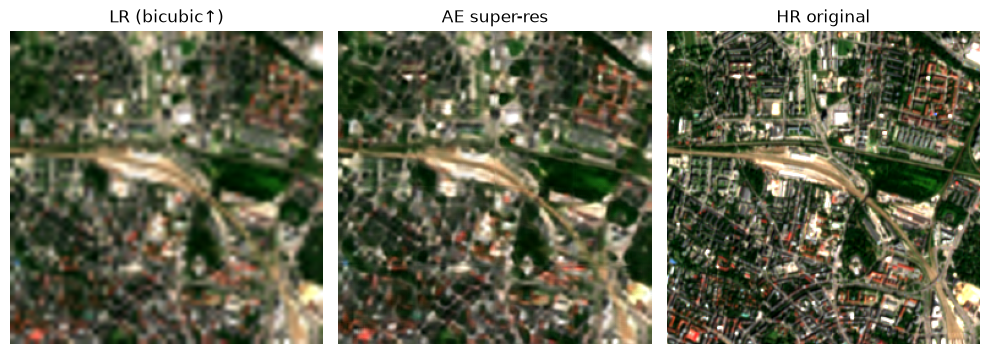

In [1]:
%matplotlib inline
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import rasterio
import tensorflow as tf

DATA = Path("../scenes") if Path("../scenes").exists() else Path("scenes")
SCALE, P, N = 4, 64, 300

hr = np.stack([rasterio.open(DATA / f"s2_urban_{b}.tif").read(1) for b in ("B04", "B03", "B02")], -1).astype(np.float32)
hr = hr[:256, :256]
lo, hi = np.percentile(hr, (2, 98))
hr = np.clip((hr - lo) / (hi - lo + 1e-6), 0, 1)

def down_up(x, s=SCALE):
    h, w = x.shape[:2]
    lr = tf.image.resize(x[None], (h // s, w // s), method="area")[0]
    return tf.image.resize(lr[None], (h, w), method="bicubic")[0].numpy()

rng = np.random.default_rng(0)
xs, ys = [], []
for _ in range(N):
    r, c = rng.integers(0, 256 - P, 2)
    y = hr[r:r+P, c:c+P]
    x = down_up(y)
    xs.append(x); ys.append(y - x)
X, R = np.stack(xs).astype(np.float32), np.stack(ys).astype(np.float32)

ae = tf.keras.Sequential([
    tf.keras.layers.Input((P, P, 3)),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.Conv2D(32, 3, strides=2, padding="same", activation="relu"),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu"),
    tf.keras.layers.Conv2D(3, 3, padding="same"),
])
ae.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
ae.fit(X, R, epochs=25, batch_size=16, verbose=0)

lr = down_up(hr)
sr = np.zeros_like(hr)
for r in range(0, 256, P):
    for c in range(0, 256, P):
        patch = lr[r:r+P, c:c+P]
        sr[r:r+P, c:c+P] = np.clip(patch + ae.predict(patch[None], verbose=0)[0], 0, 1)

mse_lr, mse_sr = float(np.mean((lr - hr)**2)), float(np.mean((sr - hr)**2))
print(f"MSE vs HR — bicubic: {mse_lr:.5f} | AE SR: {mse_sr:.5f}")

fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
for a, im, t in zip(ax, [lr, sr, hr], ["LR (bicubic↑)", "AE super-res", "HR original"]):
    a.imshow(im); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()


## Does it enhance?
A little vs bicubic - sharper edges, but no real new info (synthetic LR→HR).

## Better how?
More data, deeper residual SR, real S2 20 m→10 m pairs, SSIM/perceptual loss.
